# Vector Search Internals — Walkthrough
**Goal:** understand the math first, then NumPy, Gemini Embedding 2, Qdrant, normalization, and benchmarks. Run cells from top to bottom. Each step prints its results. **No timing results are invented.**

## 0 · Setup: API keys

Keys are read from a **`.env`** file next to this notebook. They are never written into the notebook, so it is safe to share:

```
GEMINI_API_KEY=your-google-ai-studio-key     # https://aistudio.google.com/apikey
QDRANT_URL=http://127.0.0.1:6333             # optional, defaults to local Docker 
QDRANT_API_KEY=                              # optional, only needed for Qdrant Cloud

http://127.0.0.1:6333/dashboard

```

Variables already set in the environment take priority over `.env`. The cell below only reports *whether* each key was found.

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

ENV_FILE = Path(".env")
load_dotenv(ENV_FILE, override=False)   # does not overwrite variables already in the environment

GEMINI_API_KEY = (os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY") or "").strip()
QDRANT_API_KEY = (os.environ.get("QDRANT_API_KEY") or "").strip() or None

print(".env file      :", "found" if ENV_FILE.exists() else "not found (using environment variables only)")
print("GEMINI_API_KEY :", "set" if GEMINI_API_KEY else "NOT SET - section 2 will use stand-in vectors")
print("QDRANT_URL     :", os.environ.get("QDRANT_URL", "not set - defaulting to http://127.0.0.1:6333"))
print("QDRANT_API_KEY :", "set" if QDRANT_API_KEY else "not set (fine for local Docker)")

.env file      : found
GEMINI_API_KEY : set
QDRANT_URL     : https://cf6fa5c8-ac6b-4b62-b992-2efabcc6cc32.us-east-1-1.aws.cloud.qdrant.io
QDRANT_API_KEY : set


## Step 1 — Three points and one query
A=(2,3), B=(1,2), C=(0,4); query=(2,4). Euclidean = straight-line distance (**smaller wins**). Cosine = direction similarity (**larger wins**).


**Euclidean distance** is the straight-line distance. Smaller means closer:

$$d(q, p) = \sqrt{(q_x - p_x)^2 + (q_y - p_y)^2}$$

**Cosine similarity** is the cosine of the angle between the two arrows from the origin. Larger means closer, 1 means "same direction":

$$\cos(q, p) = \frac{q \cdot p}{\lVert q \rVert \, \lVert p \rVert} = \frac{q_x p_x + q_y p_y}{\sqrt{q_x^2 + q_y^2}\,\sqrt{p_x^2 + p_y^2}}$$

In [2]:
import math
points = {"A": (2, 3), "B": (1, 2), "C": (0, 4)}
query = (2, 4)

def euclidean(a, b):
    return math.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)

def cosine(a, b):
    dot = a[0]*b[0] + a[1]*b[1]
    length_a = math.sqrt(a[0]**2 + a[1]**2)
    length_b = math.sqrt(b[0]**2 + b[1]**2)
    return dot / (length_a * length_b)

for name, point in points.items():
    print(name, point, 'distance =', round(euclidean(query, point), 4),
          'cosine =', round(cosine(query, point), 4))

A (2, 3) distance = 1.0 cosine = 0.9923
B (1, 2) distance = 2.2361 cosine = 1.0
C (0, 4) distance = 2.0 cosine = 0.8944


In [3]:
distance_ranking = sorted(points, key=lambda name: euclidean(query, points[name]))
cosine_ranking = sorted(points, key=lambda name: cosine(query, points[name]), reverse=True)
print('Euclidean (nearest first):', distance_ranking)  # A, C, B
print('Cosine (most similar first):', cosine_ranking)   # B, A, C
assert distance_ranking == ['A', 'C', 'B']
assert cosine_ranking == ['B', 'A', 'C']

Euclidean (nearest first): ['A', 'C', 'B']
Cosine (most similar first): ['B', 'A', 'C']


**Why the rankings differ:** B=(1,2) is exactly half of q=(2,4), so it points in the same direction (cosine=1), but A is only 1 unit away. This is the key idea to explain during your presentation.

## Step 2 — NumPy brute-force top-k
Compare the query against **every** row. Sort scores and return the best k. The same code works in 2 dimensions or 3,072 dimensions.

# What does brute force do
Keep all vectors in a matrix: one row per stored item.

Compare the query vector against every row.

Calculate one distance or similarity score per row.

Sort scores and return the top K IDs.

In [4]:
import numpy as np
X2 = np.array(list(points.values()), dtype=float)
q2 = np.array(query, dtype=float)

def numpy_topk(X, q, k=3, metric='cosine'):
    if metric == 'euclidean':
        scores = np.sqrt(np.sum((X - q)**2, axis=1))
        order = np.argsort(scores)        # smaller is better
    elif metric == 'cosine':
        dots = X @ q
        scores = dots / (np.linalg.norm(X, axis=1) * np.linalg.norm(q))
        order = np.argsort(-scores)       # larger is better
    else:
        raise ValueError('Choose euclidean or cosine')
    return [(int(i), float(scores[i])) for i in order[:k]]

names = list(points)
for metric in ('euclidean', 'cosine'):
    result = numpy_topk(X2, q2, k=3, metric=metric)
    print(metric, [(names[i], round(score, 4)) for i, score in result])

euclidean [('A', 1.0), ('C', 2.0), ('B', 2.2361)]
cosine [('B', 1.0), ('A', 0.9923), ('C', 0.8944)]


## Step 3 — Get Gemini Embedding 2 vectors
Add `GEMINI_API_KEY=...` to a local `.env` file. This cell requests one vector per text. If no key is provided, the notebook uses clearly labelled **demo vectors**, not Gemini embeddings. Do not describe demo results as Gemini results.

pipeline:

Documents → Gemini Embedding 2 → vectors → Qdrant collection

Question → Gemini Embedding 2 → query vector → nearest vectors → matching document text

In [5]:
import os
from pathlib import Path
from dotenv import load_dotenv
load_dotenv()
texts = [
    'Python is used for data science.',
    'Qdrant stores and searches vectors.',
    'A pizza recipe uses tomatoes and cheese.',
    'Machine learning models use numerical data.',
    'A vector database can search similar documents.',
    'Bread dough rises when yeast ferments.'
]
query_text = 'How does a vector database find similar text?'
api_key = os.getenv('GEMINI_API_KEY') or os.getenv('GOOGLE_API_KEY')

if api_key:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=api_key)
    def embed_one(text):
        response = client.models.embed_content(model='gemini-embedding-2', contents=text)
        return response.embeddings[0].values
    print('Requesting real Gemini embeddings (one API call per text)...')
    X = np.array([embed_one(text) for text in texts], dtype=np.float32)
    q = np.array(embed_one(query_text), dtype=np.float32)
    source = 'REAL Gemini Embedding 2'
else:
    print('No API key: using SYNTHETIC DEMO vectors, not Gemini embeddings')
    rng = np.random.default_rng(7)
    X = rng.normal(size=(len(texts), 64)).astype(np.float32)
    q = rng.normal(size=64).astype(np.float32)
    source = 'SYNTHETIC DEMO'
print('Source:', source, '| stored matrix:', X.shape, '| query:', q.shape)

Requesting real Gemini embeddings (one API call per text)...
Source: REAL Gemini Embedding 2 | stored matrix: (6, 3072) | query: (3072,)


In [6]:
K = 3
for metric in ('euclidean', 'cosine'):
    print('\nTop 3 by', metric)
    for index, score in numpy_topk(X, q, K, metric):
        print('  ', index, round(score, 5), texts[index])


Top 3 by euclidean
   4 0.49372 A vector database can search similar documents.
   1 0.73359 Qdrant stores and searches vectors.
   3 0.84191 Machine learning models use numerical data.

Top 3 by cosine
   4 0.87812 A vector database can search similar documents.
   1 0.73093 Qdrant stores and searches vectors.
   3 0.64559 Machine learning models use numerical data.


## Step 4 — Qdrant vs NumPy (exact comparison)
Qdrant is a vector database. We create two collections over the same vectors. Start Qdrant with `docker run -d --name vector-demo -p 6333:6333 qdrant/qdrant`. If Qdrant is not running, this section reports **SKIPPED** instead of claiming success. `exact=True` requests a full scan, making the comparison fair. Qdrant cosine scores may differ slightly due to float32 rounding.

In [7]:
from qdrant_client import QdrantClient, models
url = os.getenv('QDRANT_URL', 'http://127.0.0.1:6333')
api_key = os.getenv('QDRANT_API_KEY')
config = {
    "url": url,
    "timeout": 15
}
qdrant = None
try:
    # Add API key only for HTTPS connections
    if api_key and url.startswith("https://"):
        config["api_key"] = api_key
    qdrant = QdrantClient(**config)
    qdrant.get_collections()
    print('Connected to Qdrant:', url)
except Exception as error:
    print('SKIPPED: Qdrant server not available:', type(error).__name__)

def create_collection(name, vectors, metric):
    if qdrant.collection_exists(name):
        qdrant.delete_collection(name)
    qdrant.create_collection(name, vectors_config=models.VectorParams(size=vectors.shape[1], distance=metric))
    qdrant.upload_points(name, points=[models.PointStruct(id=i, vector=vector.tolist())
                                      for i, vector in enumerate(vectors)], wait=True)

def qdrant_search(name, vector, k, exact=True):
    hits = qdrant.query_points(collection_name=name, query=vector.tolist(), limit=k,
                               search_params=models.SearchParams(exact=exact)).points
    return [(hit.id, hit.score) for hit in hits]

if qdrant is not None:
    for metric, distance in [('euclidean', models.Distance.EUCLID), ('cosine', models.Distance.COSINE)]:
        collection = 'beginner_' + metric
        create_collection(collection, X, distance)
        expected = numpy_topk(X.astype(float), q.astype(float), K, metric)
        actual = qdrant_search(collection, q, K)
        print('\n', metric, '| NumPy:', expected, '| Qdrant:', actual)
        ids_match = [i for i, s in expected] == [i for i, s in actual]
        scores_match = np.allclose([s for i, s in expected], [s for i, s in actual], atol=1e-3)
        print('IDs match:', ids_match, '| scores match:', scores_match)
        assert ids_match and scores_match, 'Investigate differences before presenting results'
else:
    print('Qdrant comparison SKIPPED (start Docker and rerun)')

Connected to Qdrant: https://cf6fa5c8-ac6b-4b62-b992-2efabcc6cc32.us-east-1-1.aws.cloud.qdrant.io

 euclidean | NumPy: [(4, 0.49371974450597556), (1, 0.7335864082720118), (3, 0.8419118547833934)] | Qdrant: [(4, 0.49371973), (1, 0.7335864), (3, 0.84191185)]
IDs match: True | scores match: True

 cosine | NumPy: [(4, 0.8781204051901232), (1, 0.7309254758742775), (3, 0.6455922188152711)] | Qdrant: [(4, 0.8781204), (1, 0.73092544), (3, 0.6455923)]
IDs match: True | scores match: True


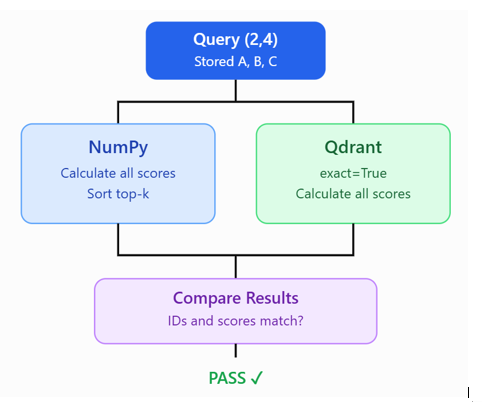

expected contains the NumPy results.

actual contains the Qdrant results.

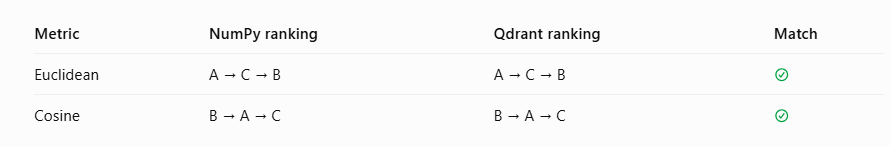

## Step 5 — Normalize: cosine = dot product
Normalization means converting a vector to a length of 1 without changing its direction. On normalized vectors, cosine and dot product are numerically equal.
Then `cosine(a,b) = dot(a,b)` because both lengths are 1. On unit vectors, Euclidean also gives the same ordering, apart from possible numerical ties.


Normalising a vector means dividing it by its length, $\hat{x} = x / \lVert x \rVert$, so that $\lVert \hat{x} \rVert = 1$.
Then the cosine formula's denominator is $1 \cdot 1$:

$$\cos(\hat{q}, \hat{x}) = \frac{\hat{q} \cdot \hat{x}}{\lVert\hat{q}\rVert\,\lVert\hat{x}\rVert} = \frac{\hat{q} \cdot \hat{x}}{1 \cdot 1} = \hat{q} \cdot \hat{x}$$

So on unit vectors **cosine similarity and dot product are the same number**, which means the same ranking. Vector databases exploit this. A dot product skips two square roots and a division per comparison, so they normalise once at insert time and then use the cheaper operation on every query.

There is a bonus. On unit vectors, Euclidean distance also gives the **same ranking**:

$$\lVert \hat{q} - \hat{x} \rVert^2 = \lVert\hat{q}\rVert^2 + \lVert\hat{x}\rVert^2 - 2\,\hat{q}\cdot\hat{x} = 2 - 2\cos(\hat{q}, \hat{x})$$

Distance is a decreasing function of cosine, so "smallest distance" means "largest cosine".

**Without normalisation, the dot product is not cosine.**

In [8]:
def normalize_rows(matrix):
    lengths = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(lengths, 1e-12)

X_unit = normalize_rows(X.astype(float))
q_unit = normalize_rows(q.astype(float).reshape(1, -1))[0]
cosine_scores = (X.astype(float) @ q.astype(float)) / (np.linalg.norm(X, axis=1) * np.linalg.norm(q))
dot_scores = X_unit @ q_unit
print('Max cosine vs normalized-dot difference:', np.max(np.abs(cosine_scores - dot_scores)))
print('Cosine ranking:', np.argsort(-cosine_scores).tolist())
print('Unit dot ranking:', np.argsort(-dot_scores).tolist())
assert np.allclose(cosine_scores, dot_scores, atol=1e-5)

# A tiny example where raw dot and cosine rank differently
print('Raw 2D dot scores:', X2 @ q2)
print('Normalized 2D dot scores:', normalize_rows(X2) @ normalize_rows(q2.reshape(1,-1))[0])

Max cosine vs normalized-dot difference: 1.2625391621057247e-08
Cosine ranking: [4, 1, 3, 0, 5, 2]
Unit dot ranking: [4, 1, 3, 0, 5, 2]
Raw 2D dot scores: [16. 10. 16.]
Normalized 2D dot scores: [0.99227788 1.         0.89442719]


## Step 6 — Benchmark at 1,000 and 10,000 vectors
To avoid thousands of paid embedding requests, benchmark **synthetic vectors** with the same dimension as Gemini Embedding 2 (3,072 if the default is used). Use the **same data and queries** for both implementations. Results are measured on your machine, not pre-filled. This optional step may take time and memory. For HNSW to be meaningful, use a running Qdrant server and allow indexing to finish; the code checks index status and labels runs without an index.

In [10]:
import time

def timed_numpy(data, queries, k=10):
    times = []
    for vector in queries:
        start = time.perf_counter()
        numpy_topk(data, vector, k, 'cosine')
        times.append((time.perf_counter() - start)*1000)
    return float(np.median(times))

# Change to True when ready to run the benchmark (Qdrant must be running).
if 'RUN_BENCHMARK' not in os.environ:
    RUN_BENCHMARK = False
else:
    RUN_BENCHMARK = os.environ['RUN_BENCHMARK'].lower() == 'true'

if RUN_BENCHMARK and qdrant is None:
    print('SKIPPED: start the Qdrant server before benchmarking')
elif RUN_BENCHMARK:
    rng = np.random.default_rng(42)
    dim = 3072
    for count in (1000, 10000):
        data = rng.normal(size=(count, dim)).astype(np.float32)
        data = normalize_rows(data).astype(np.float32)
        queries_bench = normalize_rows(rng.normal(size=(10, dim)).astype(np.float32)).astype(np.float32)
        name = 'beginner_benchmark_' + str(count)
        create_collection(name, data, models.Distance.COSINE)
        # Force indexing even for small collections; may take time.
        qdrant.update_collection(name,
            hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100, full_scan_threshold=10),
            optimizers_config=models.OptimizersConfigDiff(indexing_threshold=10))
        deadline = time.time() + 180
        while time.time() < deadline:
            info = qdrant.get_collection(name)
            if (info.indexed_vectors_count or 0) >= count:
                break
            time.sleep(2)
        indexed = (qdrant.get_collection(name).indexed_vectors_count or 0) >= count
        numpy_ms = timed_numpy(data, queries_bench)
        qdrant_times = []
        recalls = []
        for vector in queries_bench:
            truth = {i for i, score in numpy_topk(data, vector, 10, 'cosine')}
            start = time.perf_counter()
            hits = qdrant_search(name, vector, 10, exact=False)
            qdrant_times.append((time.perf_counter()-start)*1000)
            recalls.append(len(truth & {i for i, score in hits}) / 10)
        print(f'N={count:,} | NumPy {numpy_ms:.2f} ms | Qdrant round trip {np.median(qdrant_times):.2f} ms | recall@10 {np.mean(recalls):.3f} | HNSW indexed={indexed}')
else:
    print('Benchmark not run. Set RUN_BENCHMARK = True after starting Qdrant.')

N=1,000 | NumPy 5.23 ms | Qdrant round trip 61.92 ms | recall@10 0.980 | HNSW indexed=True
N=10,000 | NumPy 80.08 ms | Qdrant round trip 74.25 ms | recall@10 0.440 | HNSW indexed=True


benchmark results are very useful because they demonstrate why vector databases use HNSW indexing, and the trade-off between search speed and accuracy.

# Understanding Recall@10
Recall@10 tells us how many of the actual 10 nearest neighbors Qdrant successfully retrieved.

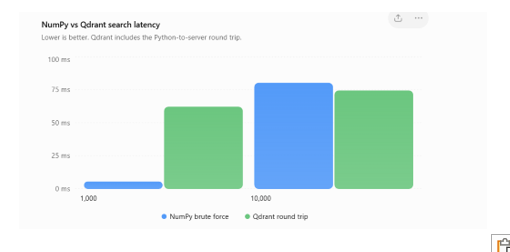

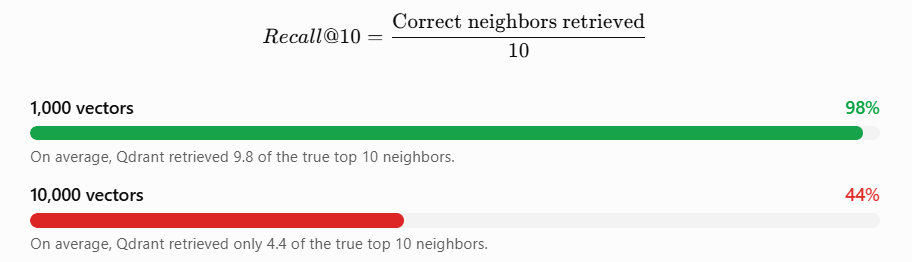

## Presentation conclusion
1. A vector DB stores arrays of numbers and computes similarity to a query. 2. Euclidean cares about absolute distance; cosine cares about direction. 3. NumPy brute force checks all vectors. 4. Qdrant can produce the same exact ranking. 5. Unit normalization makes cosine equal dot product. 6. HNSW navigates a neighbor graph to avoid most comparisons; it trades indexing work/memory for faster approximate search, with possible recall loss.